Practical NO.03(B)  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title -  Implement K-Nearest Neighbours‟ algorithm on Social network ad dataset. Compute confusion matrix, accuracy, error rate, precision and recall on 
the given dataset.  
Dataset link:https://www.kaggle.com/datasets/rakeshrau/social-network-ads

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
# loading social ad file from practical desktop folder
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\Social_Network_Ads.csv"
df = pd.read_csv(path)
# verifying data matrix structure shape
print("Dataset Shape Matrix:", df.shape)
df.head()

Dataset Shape Matrix: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [2]:
# dropping user id and gender strings to isolate integer inputs
# age and estimated salary are features, purchased is target
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']
# splitting values into 75% train and 25% validation test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
# scaling values using standard scaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training partition data ready:", X_train.shape)

Training partition data ready: (300, 2)


In [3]:
# initializing knn classifier using standard 5 neighbors metric
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn.fit(X_train, y_train)
# predicting outcomes for test records
y_pred = knn.predict(X_test)
# calculating explicit error rate variable required by manual objectives
acc = accuracy_score(y_test, y_pred)
error_rate = 1.0 - acc
print("=== KNN Performance Metrics Summary ===")
print("Overall Model Accuracy:", round(acc * 100, 2), "%")
print("Computed Error Rate Score:", round(error_rate * 100, 2), "%\n")
# displays full precision and recall breakdown matrix text
print(classification_report(y_test, y_pred))

=== KNN Performance Metrics Summary ===
Overall Model Accuracy: 93.0 %
Computed Error Rate Score: 7.0 %

              precision    recall  f1-score   support

           0       0.95      0.94      0.94        63
           1       0.89      0.92      0.91        37

    accuracy                           0.93       100
   macro avg       0.92      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



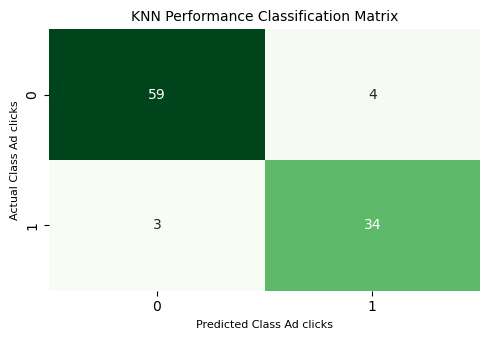

In [4]:
# generating the core evaluation confusion hits grid matrix
cm = confusion_matrix(y_test, y_pred)
# keeping plot size at 5x3.5 to minimize total print sheet counts
plt.figure(figsize=(5, 3.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('KNN Performance Classification Matrix', fontsize=10)
plt.xlabel('Predicted Class Ad clicks', fontsize=8)
plt.ylabel('Actual Class Ad clicks', fontsize=8)
plt.tight_layout() # strips away broad margin spaces
plt.show()